In [ ]:
# Cell 1 — Environment check
import torch, os
print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

# Make sure runtime is GPU (Runtime > Change runtime type > T4/A100) before training

!pip install -q timm

GPU available: False
Device: CPU only


In [ ]:
# Cell 3 — Download MeatScan directly from Zenodo (skip local upload entirely)
!wget -q --show-progress "https://zenodo.org/records/16764338/files/MeatScan_Dataset.rar?download=1" -O /content/MeatScan_Dataset.rar

/content/MeatScan_D 100%[===================>]  23.67G   107MB/s    in 4m 31s  


In [ ]:
# Cell 4 — Install unrar and extract
!apt-get -qq install unrar
!unrar x -y /content/MeatScan_Dataset.rar /content/meatscan_data/

Streaming output truncated to the last 5000 lines.
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1335).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1336).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1337).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1338).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1339).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (134).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1340).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Spoiled (1341).jpg      69%  OK 
Extracting  /content/meatscan_data/MeatScan_Dataset/Spoiled_CowMeat/Sp

In [ ]:
# Cell 2 — Inspect what's actually in the Colab session
import os

def show_tree(path, prefix="", max_depth=3, depth=0):
    if depth > max_depth:
        return
    try:
        entries = sorted(os.listdir(path))
    except (NotADirectoryError, PermissionError):
        return
    for entry in entries[:20]:  # cap listing so it doesn't flood output
        full = os.path.join(path, entry)
        print(prefix + entry)
        if os.path.isdir(full):
            show_tree(full, prefix + "  ", max_depth, depth + 1)

print("Contents of /content:")
show_tree("/content", max_depth=2)

Contents of /content:
.config
  .last_opt_in_prompt.yaml
  .last_survey_prompt.yaml
  .last_update_check.json
  active_config
  config_sentinel
  configurations
    config_default
  default_configs.db
  gce
  hidden_gcloud_config_universe_descriptor_data_cache_configs.db
  logs
    2026.09.16
images.jpg
sample_data
  README.md
  anscombe.json
  california_housing_test.csv
  california_housing_train.csv
  mnist_test.csv
  mnist_train_small.csv


In [ ]:
# Cell 5 — Peek inside the class folders + metadata CSV
import os
import pandas as pd

base = "/content/meatscan_data/MeatScan_Dataset"

for folder in ["Fresh_CowMeat", "Spoiled_CowMeat"]:
    full_path = os.path.join(base, folder)
    items = os.listdir(full_path)
    print(f"{folder}: {len(items)} items")
    print("  Sample entries:", items[:5])
    # Check if these are files or subdirectories
    sample_full = os.path.join(full_path, items[0])
    print("  Is directory:", os.path.isdir(sample_full))
    print()

# Peek at metadata
meta_path = os.path.join(base, "MeatScan_Metadata.csv")
df = pd.read_csv(meta_path)
print("Metadata shape:", df.shape)
print("Metadata columns:", list(df.columns))
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/meatscan_data/MeatScan_Dataset/Fresh_CowMeat'

In [ ]:
# Cell 6 (parallelized + progress-visible)
import os
from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed

base = "/content/meatscan_data/MeatScan_Dataset"
class_folders = {"Fresh_CowMeat": 0, "Spoiled_CowMeat": 1}

all_files = []
for folder, label in class_folders.items():
    folder_path = os.path.join(base, folder)
    for fname in os.scandir(folder_path):
        if fname.name.lower().endswith((".jpg", ".jpeg", ".png")):
            all_files.append((fname.path, label, folder))

print(f"Checking {len(all_files)} files...")

def check_file(item):
    path, label, folder = item
    try:
        with Image.open(path) as img:
            img.convert("RGB").load()
        return (path, label, True)
    except Exception:
        return (path, label, False)

filepaths, labels = [], []
skipped = {"Fresh_CowMeat": 0, "Spoiled_CowMeat": 0}

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(check_file, item) for item in all_files]
    for i, future in enumerate(as_completed(futures)):
        path, label, ok = future.result()
        if ok:
            filepaths.append(path)
            labels.append(label)
        else:
            folder_name = "Fresh_CowMeat" if label == 0 else "Spoiled_CowMeat"
            skipped[folder_name] += 1

        if (i + 1) % 1000 == 0:
            print(f"  {i+1}/{len(all_files)} checked...")

print("Total usable images:", len(filepaths))
print("Fresh:", labels.count(0), "(skipped", skipped["Fresh_CowMeat"], ")")
print("Spoiled:", labels.count(1), "(skipped", skipped["Spoiled_CowMeat"], ")")

FileNotFoundError: [Errno 2] No such file or directory: '/content/meatscan_data/MeatScan_Dataset/Fresh_CowMeat'

In [ ]:
# Cell 6b — One-time resize cache (run this once, after Cell 6's filtering)
import os
from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed

cache_dir = "/content/meatscan_resized"
os.makedirs(cache_dir, exist_ok=True)

IMG_SIZE = 224

def resize_and_cache(item):
    idx, path, label = item
    cls_name = "fresh" if label == 0 else "spoiled"
    out_path = os.path.join(cache_dir, f"{cls_name}_{idx}.jpg")
    try:
        with Image.open(path) as img:
            img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            img.save(out_path, "JPEG", quality=90)
        return (out_path, label, True)
    except Exception:
        return (None, label, False)

items = list(enumerate(zip(filepaths, labels)))
items = [(idx, p, l) for idx, (p, l) in items]

cached_paths, cached_labels = [], []

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(resize_and_cache, item) for item in items]
    for i, future in enumerate(as_completed(futures)):
        out_path, label, ok = future.result()
        if ok:
            cached_paths.append(out_path)
            cached_labels.append(label)
        if (i + 1) % 1000 == 0:
            print(f"  {i+1}/{len(items)} cached...")

print(f"Cached {len(cached_paths)} resized images to {cache_dir}")

# Overwrite filepaths/labels so Cell 7's split uses the cached versions
filepaths, labels = cached_paths, cached_labels

  1000/10561 cached...
  2000/10561 cached...
  3000/10561 cached...
  4000/10561 cached...
  5000/10561 cached...
  6000/10561 cached...
  7000/10561 cached...
  8000/10561 cached...
  9000/10561 cached...
  10000/10561 cached...
Cached 10561 resized images to /content/meatscan_resized


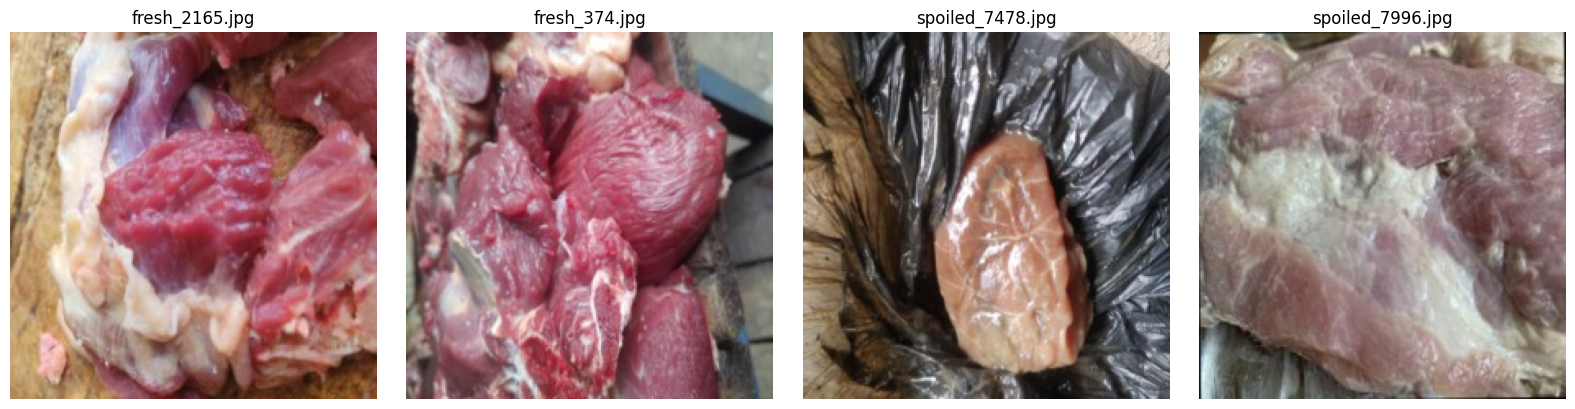

In [ ]:
# Cell 6c — Visual sanity check on cached images
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

samples = [
    ("/content/meatscan_resized/fresh_0.jpg", "Fresh sample"),
    ("/content/meatscan_resized/spoiled_1.jpg", "Spoiled sample"),
]

# Grab a couple more random ones from whatever actually exists in the cache,
# since exact filenames depend on indexing order from Cell 6
import os, random
cached_files = os.listdir("/content/meatscan_resized")
fresh_files = [f for f in cached_files if f.startswith("fresh_")]
spoiled_files = [f for f in cached_files if f.startswith("spoiled_")]

picks = [
    os.path.join("/content/meatscan_resized", random.choice(fresh_files)),
    os.path.join("/content/meatscan_resized", random.choice(fresh_files)),
    os.path.join("/content/meatscan_resized", random.choice(spoiled_files)),
    os.path.join("/content/meatscan_resized", random.choice(spoiled_files)),
]

for ax, path in zip(axes, picks):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(os.path.basename(path))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 7 — Stratified 70/15/15 split
from sklearn.model_selection import train_test_split

# First split off 70% train, 30% temp
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    filepaths, labels, test_size=0.30, stratify=labels, random_state=42
)
# Split temp into 15% val, 15% test (i.e. 50/50 of the remaining 30%)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42
)

print(f"Train: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}")
print(f"Train class balance — Fresh: {train_labels.count(0)}, Spoiled: {train_labels.count(1)}")

NameError: name 'filepaths' is not defined

In [ ]:
# Cell 8 — Dataset class + transforms
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageFile

# Allow loading truncated JPEGs
ImageFile.LOAD_TRUNCATED_IMAGES = True

IMG_SIZE = 224  # ReXNet-150 default input size

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])


class MeatScanDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            img = img.convert("RGB")
            img = self.transform(img)

        return img, self.labels[idx]


train_ds = MeatScanDataset(train_paths, train_labels, train_transform)
val_ds = MeatScanDataset(val_paths, val_labels, eval_transform)
test_ds = MeatScanDataset(test_paths, test_labels, eval_transform)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)

print("Loaders ready.")

NameError: name 'train_paths' is not defined

In [ ]:
# Cell 9 — ReXNet-150 model setup via timm
import timm
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model("rexnet_150", pretrained=True, num_classes=2)
model = model.to(device)

print(model.default_cfg.get("input_size"))  # sanity check pretrained input resolution
print("Model loaded on:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B / 39.2MB            

model.safetensors: downloading bytes:           |  0.00B            

(3, 224, 224)
Model loaded on: cpu


In [ ]:
# Cell 10 — Loss, optimizer, scheduler
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

EPOCHS = 15

In [ ]:
# Cell 11 — Training loop with validation + best-checkpoint saving
import copy
import time

scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, train_mode=True):
    model.train() if train_mode else model.eval()

    total_loss, correct, total = 0.0, 0, 0

    print("Starting", "training" if train_mode else "validation")

    with torch.set_grad_enabled(train_mode):
        for i, (imgs, labels) in enumerate(loader):

            if i % 20 == 0:
                print(f"Batch {i}/{len(loader)}")

            imgs = imgs.to(device)
            labels = labels.to(device)

            if train_mode:
                optimizer.zero_grad(set_to_none=True)

                with torch.amp.autocast("cuda"):
                    outputs = model(imgs)
                    loss = criterion(outputs, labels)

                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            else:
                with torch.amp.autocast("cuda"):
                    outputs = model(imgs)
                    loss = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

best_val_acc = 0.0
best_model_state = None
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    start = time.time()
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start
    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | "
          f"{elapsed:.1f}s")

print(f"\nBest val accuracy: {best_val_acc:.4f}")
model.load_state_dict(best_model_state)  # restore best checkpoint for evaluation

Starting training
Batch 0/231
Batch 20/231
Batch 40/231
Batch 60/231
Batch 80/231
Batch 100/231
Batch 120/231
Batch 140/231
Batch 160/231
Batch 180/231
Batch 200/231
Batch 220/231
Starting validation
Batch 0/50
Batch 20/50
Batch 40/50
Epoch 1/15 | Train Loss: 0.1621 Acc: 0.9608 | Val Loss: 0.0432 Acc: 0.9912 | 36.1s
Starting training
Batch 0/231
Batch 20/231
Batch 40/231
Batch 60/231
Batch 80/231
Batch 100/231
Batch 120/231
Batch 140/231
Batch 160/231
Batch 180/231
Batch 200/231
Batch 220/231
Starting validation
Batch 0/50
Batch 20/50
Batch 40/50
Epoch 2/15 | Train Loss: 0.0112 Acc: 0.9963 | Val Loss: 0.0273 Acc: 0.9949 | 35.8s
Starting training
Batch 0/231
Batch 20/231
Batch 40/231
Batch 60/231
Batch 80/231
Batch 100/231
Batch 120/231
Batch 140/231
Batch 160/231
Batch 180/231
Batch 200/231
Batch 220/231
Starting validation
Batch 0/50
Batch 20/50
Batch 40/50
Epoch 3/15 | Train Loss: 0.0127 Acc: 0.9968 | Val Loss: 0.0386 Acc: 0.9918 | 34.5s
Starting training
Batch 0/231
Batch 20/231
Bat

<All keys matched successfully>

In [ ]:
# Cell 12 — Save checkpoint to Drive
from google.colab import drive
drive.mount('/content/drive')
import torch
import os
save_dir = "/content/drive/MyDrive/CSRP_Beef_Quality/checkpoints"
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, "rexnet150_freshness_best.pth")

model = timm.create_model("rexnet_150", pretrained=False, num_classes=2)
best_model_state = torch.load(os.path.join(ckpt_dir, "rexnet150_freshness_best.pth"), map_location=device)
model.load_state_dict(best_model_state)
model = model.to(device).eval()

# Marbling model (5 classes)
model_marbling = timm.create_model("rexnet_150", pretrained=False, num_classes=5)
best_model_state_m = torch.load(os.path.join(ckpt_dir, "rexnet150_marbling_best.pth"), map_location=device)
model_marbling.load_state_dict(best_model_state_m)
model_marbling = model_marbling.to(device).eval()
torch.save(best_model_state, save_path)
print(f"Saved to: {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


NameError: name 'best_model_state' is not defined

In [ ]:
# Cell 13 — Test set evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import numpy as np

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average="binary")
rec = recall_score(all_labels, all_preds, average="binary")
f1 = f1_score(all_labels, all_preds, average="binary")
cm = confusion_matrix(all_labels, all_preds)

print(f"Test Accuracy:  {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall:    {rec:.4f}")
print(f"Test F1-score:  {f1:.4f}")
print("\nConfusion Matrix (rows=actual, cols=predicted):")
print(f"           Pred Fresh  Pred Spoiled")
print(f"Fresh        {cm[0][0]:<10}  {cm[0][1]}")
print(f"Spoiled      {cm[1][0]:<10}  {cm[1][1]}")
print("\nFull classification report:")
print(classification_report(all_labels, all_preds, target_names=["Fresh", "Spoiled"]))

NameError: name 'test_loader' is not defined

In [ ]:
from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Saving images.jpg to images (1).jpg
Prediction: Spoiled
Confidence: 99.59%
Raw probabilities — Fresh: 0.0041, Spoiled: 0.9959


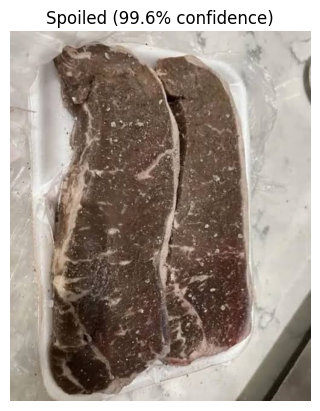

In [ ]:
# Cell 14 — Upload an image and get a live prediction
from google.colab import files
from PIL import Image
import torch.nn.functional as F

uploaded = files.upload()  # opens a file picker — choose your image
img_path = list(uploaded.keys())[0]

model.eval()
img = Image.open(img_path).convert("RGB")
img_tensor = eval_transform(img).unsqueeze(0).to(device)  # add batch dimension

with torch.no_grad():
    output = model(img_tensor)
    probs = F.softmax(output, dim=1)
    pred_idx = probs.argmax(dim=1).item()
    confidence = probs[0][pred_idx].item()

label = "Fresh" if pred_idx == 0 else "Spoiled"
print(f"Prediction: {label}")
print(f"Confidence: {confidence:.2%}")
print(f"Raw probabilities — Fresh: {probs[0][0].item():.4f}, Spoiled: {probs[0][1].item():.4f}")

# Show the image alongside the prediction
import matplotlib.pyplot as plt
plt.imshow(img)
plt.title(f"{label} ({confidence:.1%} confidence)")
plt.axis("off")
plt.show()

In [ ]:
# Cell 18 — Mount Drive (should already be mounted from Cell 12, this is just a safety check) and locate the folder
from google.colab import drive
drive.mount('/content/drive')

import subprocess
result = subprocess.run(['find', '/content/drive/MyDrive', '-iname', '*beef_marbling*', '-maxdepth', '4'],
                         capture_output=True, text=True)
print(result.stdout)

Mounted at /content/drive
/content/drive/MyDrive/beef_marbling_thesis.v6-yolov5.folder



In [ ]:
# Cell 19 — Once we find the path, inspect its structure (adjust path based on Cell 18 output)
import os

marbling_base = "/content/drive/MyDrive/beef_marbling_thesis.v6-yolov5.folder"

for split in ["train", "valid", "test"]:
    split_path = os.path.join(marbling_base, split)
    if os.path.exists(split_path):
        print(f"{split}/: {os.listdir(split_path)}")

# Check the data.yaml for class names
yaml_path = os.path.join(marbling_base, "data.yaml")
if os.path.exists(yaml_path):
    with open(yaml_path) as f:
        print("\ndata.yaml contents:")
        print(f.read())

train/: ['moderate', 'slight', 'modest', 'small', 'slightly_abundant']
valid/: ['moderate', 'modest', 'slight', 'slightly_abundant', 'small']
test/: ['slight', 'moderate', 'small', 'modest', 'slightly_abundant']


In [ ]:
# Cell 20 (parallelized copy with progress)
import os, shutil
from concurrent.futures import ThreadPoolExecutor, as_completed

drive_marbling_path = "/content/drive/MyDrive/beef_marbling_thesis.v6-yolov5.folder"
local_marbling_path = "/content/marbling_data"

if os.path.exists(local_marbling_path):
    shutil.rmtree(local_marbling_path)
os.makedirs(local_marbling_path, exist_ok=True)

# Collect all files first (preserving split/class subfolder structure)
all_files = []
for split in ["train", "valid", "test"]:
    split_path = os.path.join(drive_marbling_path, split)
    if not os.path.exists(split_path):
        continue
    for cls_name in os.listdir(split_path):
        cls_path = os.path.join(split_path, cls_name)
        if not os.path.isdir(cls_path):
            continue
        dest_cls_path = os.path.join(local_marbling_path, split, cls_name)
        os.makedirs(dest_cls_path, exist_ok=True)
        for fname in os.listdir(cls_path):
            src = os.path.join(cls_path, fname)
            dst = os.path.join(dest_cls_path, fname)
            all_files.append((src, dst))

print(f"Copying {len(all_files)} files...")

def copy_file(item):
    src, dst = item
    try:
        shutil.copy2(src, dst)
        return True
    except Exception:
        return False

with ThreadPoolExecutor(max_workers=16) as executor:
    futures = [executor.submit(copy_file, item) for item in all_files]
    for i, future in enumerate(as_completed(futures)):
        if (i + 1) % 1000 == 0:
            print(f"  {i+1}/{len(all_files)} copied...")

print("Done. Contents:", os.listdir(local_marbling_path))

Copying 9900 files...
  1000/9900 copied...
  2000/9900 copied...
  3000/9900 copied...
  4000/9900 copied...
  5000/9900 copied...
  6000/9900 copied...
  7000/9900 copied...
  8000/9900 copied...
  9000/9900 copied...
Done. Contents: ['test', 'train', 'valid']


In [ ]:
# Cell 21 (re-run on the now-complete local copy)
import os

class_to_idx = {
    "small": 0,
    "modest": 1,
    "moderate": 2,
    "slight": 3,
    "slightly_abundant": 4,
}
idx_to_class = {v: k for k, v in class_to_idx.items()}

raw_files = []
for split in ["train", "valid", "test"]:
    split_path = os.path.join(local_marbling_path, split)
    if not os.path.exists(split_path):
        continue
    for cls_name, cls_idx in class_to_idx.items():
        cls_path = os.path.join(split_path, cls_name)
        if not os.path.exists(cls_path):
            continue
        for fname in os.scandir(cls_path):
            if fname.name.lower().endswith((".jpg", ".jpeg", ".png")):
                raw_files.append((fname.path, cls_idx))

print(f"Total raw images found: {len(raw_files)}")
for cls_name, cls_idx in class_to_idx.items():
    count = sum(1 for _, l in raw_files if l == cls_idx)
    print(f"  {cls_name}: {count}")

Total raw images found: 9900
  small: 2068
  modest: 2181
  moderate: 2114
  slight: 1383
  slightly_abundant: 2154


In [ ]:
# Cell 21b — Inspect what's actually inside the "empty" class folders
import os

for split in ["train", "valid", "test"]:
    for cls_name in ["small", "slight", "slightly_abundant"]:
        cls_path = os.path.join(local_marbling_path, split, cls_name)
        if os.path.exists(cls_path):
            contents = os.listdir(cls_path)
            print(f"{split}/{cls_name}: {len(contents)} items — sample: {contents[:5]}")
        else:
            print(f"{split}/{cls_name}: folder does not exist")

train/small: 1670 items — sample: ['cow_2_2824_jpg.rf.ac429ea3848f3789db774d9c539106b5.jpg', 'cow_2_4328_jpg.rf.f77d75cccc2083018c95f535248a8a20.jpg', 'cow_2_3462_jpg.rf.cbb10ca96cca872648f0b93b19ba9917.jpg', 'cow_2_4823_jpg.rf.a97fd06e7ece4d040e35c1d38e425ef3.jpg', 'cow_2_5342_jpg.rf.b73c5485210d7425245fa45a428fe006.jpg']
train/slight: 1107 items — sample: ['cow_3_222_jpg.rf.a8c7c062acf2d7220093d3a7dee618f5.jpg', 'cow_3_729_jpg.rf.d8ede63d7fe6f7073e7a729d0ad90346.jpg', 'cow_3_3924_jpg.rf.7b077010b68aa1527759753f07e8b865.jpg', 'cow_3_3648_jpg.rf.edb7d4eca6fb7f1aad6f39f95513b35e.jpg', 'cow_3_3851_jpg.rf.9aef5b53633525a3c80db2449f95825a.jpg']
train/slightly_abundant: 1698 items — sample: ['cow_1-_5873_jpg.rf.e8204df67481c1f75188ed8a9f72413a.jpg', 'cow_1-_1164_jpg.rf.79eed54d22fd0aaaf3f87508f77c2c46.jpg', 'cow_1-_1686_jpg.rf.85c814bb99fbcfa59682317fe775fd7b.jpg', 'cow_1-_3979_jpg.rf.bd6408d9270e087d72d364991fc8c9bc.jpg', 'cow_1-_1991_jpg.rf.6b6025a09ee3b8587583c429427df390.jpg']
valid/sma

In [ ]:
# Cell 21c — Explicit per-split breakdown for modest and moderate
import os

for split in ["train", "valid", "test"]:
    for cls_name in ["modest", "moderate"]:
        cls_path = os.path.join(local_marbling_path, split, cls_name)
        if os.path.exists(cls_path):
            count = len(os.listdir(cls_path))
            print(f"{split}/{cls_name}: {count} items")
        else:
            print(f"{split}/{cls_name}: folder does not exist")

train/modest: 1742 items
train/moderate: 1703 items
valid/modest: 226 items
valid/moderate: 203 items
test/modest: 213 items
test/moderate: 208 items


In [ ]:
# Cell 22 — Filter corrupted + cache resize in one pass (marbling)
import os
from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed

cache_dir_marbling = "/content/marbling_resized"
os.makedirs(cache_dir_marbling, exist_ok=True)
IMG_SIZE = 224

def check_and_cache(item):
    idx, path, label = item
    out_path = os.path.join(cache_dir_marbling, f"{idx_to_class[label]}_{idx}.jpg")
    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            img.load()  # full decode check
            img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            img.save(out_path, "JPEG", quality=90)
        return (out_path, label, True)
    except Exception:
        return (None, label, False)

items = [(idx, path, label) for idx, (path, label) in enumerate(raw_files)]

filepaths_marbling, labels_marbling = [], []
skipped_marbling = {cls: 0 for cls in class_to_idx}

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(check_and_cache, item) for item in items]
    for i, future in enumerate(as_completed(futures)):
        out_path, label, ok = future.result()
        if ok:
            filepaths_marbling.append(out_path)
            labels_marbling.append(label)
        else:
            skipped_marbling[idx_to_class[label]] += 1
        if (i + 1) % 1000 == 0:
            print(f"  {i+1}/{len(items)} processed...")

print(f"\nUsable images: {len(filepaths_marbling)}")
for cls_name in class_to_idx:
    cls_idx = class_to_idx[cls_name]
    count = labels_marbling.count(cls_idx)
    print(f"  {cls_name}: {count} (skipped {skipped_marbling[cls_name]})")

  1000/9900 processed...
  2000/9900 processed...
  3000/9900 processed...
  4000/9900 processed...
  5000/9900 processed...
  6000/9900 processed...
  7000/9900 processed...
  8000/9900 processed...
  9000/9900 processed...

Usable images: 9900
  small: 2068 (skipped 0)
  modest: 2181 (skipped 0)
  moderate: 2114 (skipped 0)
  slight: 1383 (skipped 0)
  slightly_abundant: 2154 (skipped 0)


In [ ]:
# Cell 23 — Stratified 70/15/15 split (marbling)
from sklearn.model_selection import train_test_split

train_paths_m, temp_paths_m, train_labels_m, temp_labels_m = train_test_split(
    filepaths_marbling, labels_marbling, test_size=0.30, stratify=labels_marbling, random_state=42
)
val_paths_m, test_paths_m, val_labels_m, test_labels_m = train_test_split(
    temp_paths_m, temp_labels_m, test_size=0.50, stratify=temp_labels_m, random_state=42
)

print(f"Train: {len(train_paths_m)} | Val: {len(val_paths_m)} | Test: {len(test_paths_m)}")

Train: 6930 | Val: 1485 | Test: 1485


In [ ]:
# Cell 24 — Dataset + loaders (marbling)
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

eval_transform_m = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class MarblingDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            img = img.convert("RGB")
            img = self.transform(img)
        return img, self.labels[idx]

train_ds_m = MarblingDataset(train_paths_m, train_labels_m, eval_transform_m)
val_ds_m = MarblingDataset(val_paths_m, val_labels_m, eval_transform_m)
test_ds_m = MarblingDataset(test_paths_m, test_labels_m, eval_transform_m)

BATCH_SIZE = 32
train_loader_m = DataLoader(train_ds_m, batch_size=BATCH_SIZE, shuffle=True, num_workers=1, pin_memory=True)
val_loader_m = DataLoader(val_ds_m, batch_size=BATCH_SIZE, shuffle=False, num_workers=1, pin_memory=True)
test_loader_m = DataLoader(test_ds_m, batch_size=BATCH_SIZE, shuffle=False, num_workers=1, pin_memory=True)

print("Marbling loaders ready (num_workers=1, stable).")

Marbling loaders ready (num_workers=1, stable).


In [ ]:
# Cell 24b — Add a separate augmented training transform
train_transform_m = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Rebuild only the training dataset/loader with augmentation; val/test stay on eval_transform_m (no augmentation — we want to measure real performance there)
train_ds_m = MarblingDataset(train_paths_m, train_labels_m, train_transform_m)
train_loader_m = DataLoader(train_ds_m, batch_size=BATCH_SIZE, shuffle=True, num_workers=1, pin_memory=True)

print("Train loader rebuilt with augmentation.")

Train loader rebuilt with augmentation.


In [ ]:
# Cell 25 — ReXNet-150 model setup (marbling, 5 classes)
import torch
import timm
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_marbling = timm.create_model("rexnet_150", pretrained=True, num_classes=5)
model_marbling = model_marbling.to(device)

print(model_marbling.default_cfg.get("input_size"))
print("Model loaded on:", device)

(3, 224, 224)
Model loaded on: cuda


In [ ]:
# Cell 26 — Loss, optimizer, scheduler (marbling)
import torch.optim as optim

criterion_m = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_m = optim.AdamW(model_marbling.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler_m = optim.lr_scheduler.ReduceLROnPlateau(optimizer_m, mode="min", factor=0.5, patience=2)
EPOCHS_M = 15

In [ ]:
# Cell 27 (simplified — no AMP/GradScaler, matches the proven freshness approach)
import copy, time

def run_epoch_marbling(loader, train_mode=True):
    model_marbling.train() if train_mode else model_marbling.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(train_mode):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)

            if train_mode:
                optimizer_m.zero_grad(set_to_none=True)

            outputs = model_marbling(imgs)
            loss = criterion_m(outputs, labels)

            if train_mode:
                loss.backward()
                optimizer_m.step()

            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

best_val_acc_m = 0.0
best_model_state_m = None
history_m = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS_M):
    start = time.time()
    train_loss, train_acc = run_epoch_marbling(train_loader_m, train_mode=True)
    val_loss, val_acc = run_epoch_marbling(val_loader_m, train_mode=False)
    scheduler_m.step(val_loss)

    history_m["train_loss"].append(train_loss)
    history_m["train_acc"].append(train_acc)
    history_m["val_loss"].append(val_loss)
    history_m["val_acc"].append(val_acc)

    if val_acc > best_val_acc_m:
        best_val_acc_m = val_acc
        best_model_state_m = copy.deepcopy(model_marbling.state_dict())

    print(f"Epoch {epoch+1}/{EPOCHS_M} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | {time.time()-start:.1f}s")

print(f"\nBest val accuracy: {best_val_acc_m:.4f}")
model_marbling.load_state_dict(best_model_state_m)

Epoch 1/15 | Train Loss: 2.0347 Acc: 0.3499 | Val Loss: 1.5472 Acc: 0.4000 | 52.8s
Epoch 2/15 | Train Loss: 1.4808 Acc: 0.4316 | Val Loss: 1.3683 Acc: 0.4613 | 55.2s
Epoch 3/15 | Train Loss: 1.3418 Acc: 0.4810 | Val Loss: 1.2839 Acc: 0.4970 | 58.4s
Epoch 4/15 | Train Loss: 1.2502 Acc: 0.5378 | Val Loss: 1.2428 Acc: 0.5273 | 57.4s
Epoch 5/15 | Train Loss: 1.1655 Acc: 0.5768 | Val Loss: 1.1897 Acc: 0.5549 | 58.7s
Epoch 6/15 | Train Loss: 1.0819 Acc: 0.6264 | Val Loss: 1.1604 Acc: 0.5556 | 58.9s
Epoch 7/15 | Train Loss: 0.9799 Acc: 0.6908 | Val Loss: 1.1145 Acc: 0.6081 | 59.1s
Epoch 8/15 | Train Loss: 0.9027 Acc: 0.7434 | Val Loss: 1.0470 Acc: 0.6734 | 59.4s
Epoch 9/15 | Train Loss: 0.8104 Acc: 0.7983 | Val Loss: 1.0122 Acc: 0.6875 | 59.6s
Epoch 10/15 | Train Loss: 0.7506 Acc: 0.8371 | Val Loss: 0.9763 Acc: 0.7172 | 59.6s
Epoch 11/15 | Train Loss: 0.6865 Acc: 0.8681 | Val Loss: 0.9481 Acc: 0.7273 | 59.9s
Epoch 12/15 | Train Loss: 0.6422 Acc: 0.8968 | Val Loss: 0.9187 Acc: 0.7515 | 61.3s
E

<All keys matched successfully>

In [ ]:
# Cell 28 — Save checkpoint + test set evaluation (marbling)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Save to Drive
import os
save_dir = "/content/drive/MyDrive/CSRP_Beef_Quality/checkpoints"
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, "rexnet150_marbling_best.pth")
torch.save(best_model_state_m, save_path)
print(f"Saved to: {save_path}")

model_marbling.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader_m:
        imgs = imgs.to(device)
        outputs = model_marbling(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

class_names_m = ["small", "modest", "moderate", "slight", "slightly_abundant"]

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average="weighted")
rec = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")
cm = confusion_matrix(all_labels, all_preds)

print(f"\nTest Accuracy:  {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall:    {rec:.4f}")
print(f"Test F1-score:  {f1:.4f}")

print("\nConfusion Matrix:")
print("Rows = actual, Columns = predicted")
print("Classes:", class_names_m)
print(cm)

print("\nFull classification report:")
print(classification_report(all_labels, all_preds, target_names=class_names_m))

Saved to: /content/drive/MyDrive/CSRP_Beef_Quality/checkpoints/rexnet150_marbling_best.pth

Test Accuracy:  0.7939
Test Precision: 0.7928
Test Recall:    0.7939
Test F1-score:  0.7926

Confusion Matrix:
Rows = actual, Columns = predicted
Classes: ['small', 'modest', 'moderate', 'slight', 'slightly_abundant']
[[266  21   3  10  11]
 [ 25 252  26   3  21]
 [ 23  35 226   1  32]
 [  2   0   0 202   3]
 [ 16  33  40   1 233]]

Full classification report:
                   precision    recall  f1-score   support

            small       0.80      0.86      0.83       311
           modest       0.74      0.77      0.75       327
         moderate       0.77      0.71      0.74       317
           slight       0.93      0.98      0.95       207
slightly_abundant       0.78      0.72      0.75       323

         accuracy                           0.79      1485
        macro avg       0.80      0.81      0.80      1485
     weighted avg       0.79      0.79      0.79      1485



In [ ]:
# Cell 29 — Continue training for 15 more epochs (30 total)
EPOCHS_EXTRA = 15

for epoch in range(EPOCHS_EXTRA):
    start = time.time()
    train_loss, train_acc = run_epoch_marbling(train_loader_m, train_mode=True)
    val_loss, val_acc = run_epoch_marbling(val_loader_m, train_mode=False)
    scheduler_m.step(val_loss)

    history_m["train_loss"].append(train_loss)
    history_m["train_acc"].append(train_acc)
    history_m["val_loss"].append(val_loss)
    history_m["val_acc"].append(val_acc)

    if val_acc > best_val_acc_m:
        best_val_acc_m = val_acc
        best_model_state_m = copy.deepcopy(model_marbling.state_dict())

    current_epoch = len(history_m["train_loss"])
    print(f"Epoch {current_epoch}/30 | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | {time.time()-start:.1f}s")

print(f"\nBest val accuracy so far: {best_val_acc_m:.4f}")
model_marbling.load_state_dict(best_model_state_m)

Epoch 16/30 | Train Loss: 0.5282 Acc: 0.9631 | Val Loss: 0.8370 Acc: 0.8000 | 56.1s
Epoch 17/30 | Train Loss: 0.5106 Acc: 0.9747 | Val Loss: 0.8424 Acc: 0.7899 | 54.6s
Epoch 18/30 | Train Loss: 0.4975 Acc: 0.9807 | Val Loss: 0.8182 Acc: 0.8094 | 56.6s
Epoch 19/30 | Train Loss: 0.4920 Acc: 0.9828 | Val Loss: 0.7949 Acc: 0.8269 | 57.7s
Epoch 20/30 | Train Loss: 0.4830 Acc: 0.9847 | Val Loss: 0.7991 Acc: 0.8182 | 58.4s
Epoch 21/30 | Train Loss: 0.4762 Acc: 0.9882 | Val Loss: 0.7858 Acc: 0.8283 | 58.9s
Epoch 22/30 | Train Loss: 0.4702 Acc: 0.9899 | Val Loss: 0.7748 Acc: 0.8337 | 59.4s
Epoch 23/30 | Train Loss: 0.4661 Acc: 0.9905 | Val Loss: 0.7756 Acc: 0.8236 | 59.5s
Epoch 24/30 | Train Loss: 0.4597 Acc: 0.9932 | Val Loss: 0.7557 Acc: 0.8404 | 59.4s
Epoch 25/30 | Train Loss: 0.4571 Acc: 0.9954 | Val Loss: 0.7540 Acc: 0.8364 | 59.8s
Epoch 26/30 | Train Loss: 0.4527 Acc: 0.9961 | Val Loss: 0.7441 Acc: 0.8451 | 60.2s
Epoch 27/30 | Train Loss: 0.4463 Acc: 0.9964 | Val Loss: 0.7321 Acc: 0.8519 

<All keys matched successfully>

In [ ]:
# Cell 30 — Save final checkpoint + test set evaluation (30-epoch marbling model)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

save_path = "/content/drive/MyDrive/CSRP_Beef_Quality/checkpoints/rexnet150_marbling_best.pth"
torch.save(best_model_state_m, save_path)
print(f"Saved to: {save_path}")

model_marbling.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader_m:
        imgs = imgs.to(device)
        outputs = model_marbling(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

class_names_m = ["small", "modest", "moderate", "slight", "slightly_abundant"]

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average="weighted")
rec = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")
cm = confusion_matrix(all_labels, all_preds)

print(f"\nTest Accuracy:  {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall:    {rec:.4f}")
print(f"Test F1-score:  {f1:.4f}")

print("\nConfusion Matrix:")
print("Classes:", class_names_m)
print(cm)

print("\nFull classification report:")
print(classification_report(all_labels, all_preds, target_names=class_names_m))

Saved to: /content/drive/MyDrive/CSRP_Beef_Quality/checkpoints/rexnet150_marbling_best.pth

Test Accuracy:  0.8498
Test Precision: 0.8497
Test Recall:    0.8498
Test F1-score:  0.8497

Confusion Matrix:
Classes: ['small', 'modest', 'moderate', 'slight', 'slightly_abundant']
[[282  13   3   6   7]
 [ 17 272  17   0  21]
 [  8  28 249   0  32]
 [  2   0   0 201   4]
 [  5  23  37   0 258]]

Full classification report:
                   precision    recall  f1-score   support

            small       0.90      0.91      0.90       311
           modest       0.81      0.83      0.82       327
         moderate       0.81      0.79      0.80       317
           slight       0.97      0.97      0.97       207
slightly_abundant       0.80      0.80      0.80       323

         accuracy                           0.85      1485
        macro avg       0.86      0.86      0.86      1485
     weighted avg       0.85      0.85      0.85      1485



In [ ]:
# Verify the marbling checkpoint survived
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = "/content/drive/MyDrive/CSRP_Beef_Quality/checkpoints"
print(os.listdir(checkpoint_dir))

Mounted at /content/drive
['rexnet150_freshness_best.pth', 'rexnet150_marbling_best.pth']


In [ ]:
# API Cell 1 (run this, then RESTART RUNTIME before anything else)
!pip install -q "rembg[cpu]" fastapi uvicorn nest-asyncio pyngrok python-multipart timm
!pip install -q --upgrade Pillow
import os
os.kill(os.getpid(), 9)  # forces runtime restart automatically

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 238.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 12.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.0 which is incompatible.


In [ ]:
# API Cell 2 — Imports and device setup
import torch
import timm
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms
import torch.nn.functional as F
import io

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [ ]:
# API Cell 3 — Load both trained models from Drive
from google.colab import drive
drive.mount('/content/drive')

CKPT_DIR = "/content/drive/MyDrive/CSRP_Beef_Quality/checkpoints"

# Freshness model (2 classes: fresh/spoiled)
model_freshness = timm.create_model("rexnet_150", pretrained=False, num_classes=2)
model_freshness.load_state_dict(torch.load(
    f"{CKPT_DIR}/rexnet150_freshness_best.pth", map_location=device))
model_freshness = model_freshness.to(device).eval()

# Marbling model (5 classes)
model_marbling = timm.create_model("rexnet_150", pretrained=False, num_classes=5)
model_marbling.load_state_dict(torch.load(
    f"{CKPT_DIR}/rexnet150_marbling_best.pth", map_location=device))
model_marbling = model_marbling.to(device).eval()

print("Both models loaded.")

Mounted at /content/drive
Both models loaded.


In [ ]:
# API Cell 4 — Preprocessing transform (same as training)
cnn_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

idx_to_marbling = {
    0: "small", 1: "modest", 2: "moderate",
    3: "slight", 4: "slightly_abundant"
}
marbling_grade_map = {
    "slightly_abundant": 30, "moderate": 25,
    "modest": 20, "slight": 15, "small": 10
}

In [ ]:
# API Cell 5 — HSV Fat Ratio Module (adapted from groupmate's implementation)
from rembg import remove as remove_bg

def estimate_fat_ratio(img_rgb: Image.Image):
    """
    Estimates visible fat ratio using AI background removal + HSV thresholding.
    Input:  PIL.Image (RGB)
    Output: (r_fat: float, fat_tier: str)
    """
    # Convert PIL to OpenCV BGR format
    img_bgr = cv2.cvtColor(np.array(img_rgb), cv2.COLOR_RGB2BGR)
    img_bgr = cv2.resize(img_bgr, (800, 800))

    # Step 1: AI background removal → meat mask
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    result = remove_bg(rgb)  # returns RGBA numpy array

    result_np = np.array(result)
    alpha = result_np[:, :, 3] if result_np.shape[2] == 4 \
            else np.ones(result_np.shape[:2], dtype=np.uint8) * 255

    meat_mask = np.where(alpha > 127, 255, 0).astype(np.uint8)

    # Clean mask with morphological ops
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    meat_mask = cv2.morphologyEx(meat_mask, cv2.MORPH_CLOSE, kernel)
    meat_mask = cv2.morphologyEx(meat_mask, cv2.MORPH_OPEN, kernel)

    # Step 2: Isolate meat region
    meat_bgr = cv2.bitwise_and(img_bgr, img_bgr, mask=meat_mask)

    # Step 3: HSV fat detection within meat region
    hsv = cv2.cvtColor(meat_bgr, cv2.COLOR_BGR2HSV)
    lower_fat = np.array([0, 0, 120])
    upper_fat = np.array([180, 120, 255])
    fat_mask = cv2.inRange(hsv, lower_fat, upper_fat)
    fat_mask = cv2.bitwise_and(fat_mask, meat_mask)  # exclude background

    # Step 4: Compute Rfat
    fat_pixels = cv2.countNonZero(fat_mask)
    meat_pixels = cv2.countNonZero(meat_mask)

    r_fat = (fat_pixels / meat_pixels * 100) if meat_pixels > 0 else 0.0

    # Categorize per paper's thresholds
    if r_fat < 1.0:
        fat_tier = "None"
    elif r_fat < 15.0:
        fat_tier = "Small"
    else:
        fat_tier = "Large"

    return round(r_fat, 2), fat_tier

In [ ]:
# API Cell 6 — Unified prediction pipeline
def predict_beef_quality(img: Image.Image):
    # Module A: Freshness
    tensor = cnn_transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs_f = F.softmax(model_freshness(tensor), dim=1)
        pred_f = probs_f.argmax(dim=1).item()
        conf_f = probs_f[0][pred_f].item()

    freshness_label = "Fresh" if pred_f == 0 else "Spoiled"
    f_freshness = 50 if pred_f == 0 else 0

    # Module B: Marbling
    with torch.no_grad():
        probs_m = F.softmax(model_marbling(tensor), dim=1)
        pred_m = probs_m.argmax(dim=1).item()
        conf_m = probs_m[0][pred_m].item()

    marbling_label = idx_to_marbling[pred_m]
    m_grade = marbling_grade_map[marbling_label]

    # Module C: HSV Fat Ratio
    r_fat, fat_tier = estimate_fat_ratio(img)

    # Aggregate Layer: MQS
    mqs = f_freshness + m_grade + min(r_fat, 20)
    if freshness_label == "Spoiled":
        mqs = min(mqs, 50)  # safety cap

    return {
        "freshness": freshness_label,
        "freshness_confidence": round(conf_f * 100, 1),
        "marbling": marbling_label,
        "marbling_confidence": round(conf_m * 100, 1),
        "fat_ratio_percent": round(r_fat, 2),
        "fat_ratio_category": fat_tier,
        "meat_quality_score": round(mqs, 1)
    }

In [ ]:
# API Cell 7 — FastAPI app
from fastapi import FastAPI, File, UploadFile
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(title="Beef Quality Assessment API")

# Allow requests from your Next.js frontend (any origin for demo purposes)
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["*"],
    allow_headers=["*"],
)

@app.get("/")
def root():
    return {"status": "Beef Quality API is running"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    # Read uploaded image bytes
    contents = await file.read()
    img = Image.open(io.BytesIO(contents)).convert("RGB")

    result = predict_beef_quality(img)
    return result

In [ ]:
# API Cell 8 (fixed)
import nest_asyncio
import uvicorn
import asyncio
from pyngrok import ngrok, conf

nest_asyncio.apply()

NGROK_TOKEN = "3KP5ZoskGjlVtNlec81alWzQf7x_5yRiLS25SjQsv9uVJnpjL"
conf.get_default().auth_token = NGROK_TOKEN

ngrok.kill()

public_url = ngrok.connect(8000)
print("=" * 50)
print(f"Public API URL: {public_url}")
print(f"Predict endpoint: {public_url}/predict")
print("=" * 50)

# Use asyncio directly instead of uvicorn.run()
config = uvicorn.Config(app, host="0.0.0.0", port=8000, loop="asyncio")
server = uvicorn.Server(config)
await server.serve()

Public API URL: NgrokTunnel: "https://justify-nutcase-flatten.ngrok-free.dev" -> "http://localhost:8000"
Predict endpoint: NgrokTunnel: "https://justify-nutcase-flatten.ngrok-free.dev" -> "http://localhost:8000"/predict


INFO:     Started server process [4476]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "OPTIONS /predict HTTP/1.1" 200 OK


  0%|                                              | 0.00/1.02G [00:00<?, ?B/s]

INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "OPTIONS /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "OPTIONS /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66cd:0 - "POST /predict HTTP/1.1" 200 OK
INFO:     2001:4450:818e:4a00:890b:c3cd:12fd:66c